# Setup

In [1]:
!pip install -qU langchain
!pip install -qU langchain-google-genai
!pip install -qU langchain-huggingface
!pip install -qU langchain-qdrant
!pip install -qU langchain-community
!pip install -qU langgraph
!pip install fastembed
!pip install datasets
# !pip install -U "fsspec[http]==2024.10.0"

   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 42.0/42.0 kB 2.1 MB/s eta 0:00:00
   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 1.4/1.4 MB 33.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-generativeai 0.8.4 requires google-ai-generativelanguage==0.6.15, but you have google-ai-generativelanguage 0.6.17 which is incompatible.
   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 363.4/363.4 MB 3.7 MB/s eta 0:00:00
   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 13.8/13.8 MB 61.6 MB/s eta 0:00:00
   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â

# Code

In this assignment, you will need to set up and use
1. LangSmith to monitor your agent.
2. Use hybrid search to improve your retriever
3. Use a reranker to improve your search result.



## TODO 0: Set up LangSmith

Create a LangSmith account and set up tracing for this assignment. https://www.smith.langchain.com/.

No need to configure, just add your LangSmith API key.

In [3]:
import os
from google.colab import userdata

os.environ["GOOGLE_API_KEY"] = userdata.get('gemini_api_key')

In [4]:
os.environ["LANGSMITH_TRACING"]="true"
os.environ["LANGSMITH_ENDPOINT"]="https://api.smith.langchain.com"
os.environ["LANGSMITH_API_KEY"]= userdata.get('langsmith_api_key')
os.environ["LANGSMITH_PROJECT"]="Lab10_RAG"

In [5]:
os.environ["LANGCHAIN_TRACING_V2"] = "true"

## Components

We will be using Gemini as our LLM. Feel free to try out others if you want.

In [6]:
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model="gemini-2.0-flash-001")

For our sentence embeddings, we will use [ModernBERT](https://arxiv.org/abs/2412.13663) trained by Alibaba as it is small and performant.

In [7]:
from langchain_huggingface import HuggingFaceEmbeddings

model_kwargs = {'trust_remote_code': True}
embeddings = HuggingFaceEmbeddings(model_name="Alibaba-NLP/gte-modernbert-base",model_kwargs=model_kwargs)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/205 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/12.8k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.18k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/298M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.58M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

Likewise, the reranker is also based on the ModernBERT trained by Alibaba.

In [8]:
from langchain.retrievers import ContextualCompressionRetriever
from langchain.retrievers.document_compressors import CrossEncoderReranker
from langchain_community.cross_encoders import HuggingFaceCrossEncoder

model = HuggingFaceCrossEncoder(model_name="Alibaba-NLP/gte-reranker-modernbert-base")

config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/598M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/21.0k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.58M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

For our dataset, we will be using SQuAD v2 dataset.

In [9]:
import datasets

ds = datasets.load_dataset("rajpurkar/squad_v2", split="validation")

README.md:   0%|          | 0.00/8.92k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/16.4M [00:00<?, ?B/s]

validation-00000-of-00001.parquet:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/130319 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11873 [00:00<?, ? examples/s]

## Indexing

In [10]:
from langchain_core.documents import Document

In [11]:
all_docs = [Document(text) for text in  list(set(ds["context"]))]
print(len(all_docs))

1204


In [12]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=2000,  # chunk size (characters)
    chunk_overlap=200,  # chunk overlap (characters)
    add_start_index=True,  # track index in original document
)
all_splits = text_splitter.split_documents(all_docs)

print(f"Split wiki abstract into {len(all_splits)} sub-documents.")

Split wiki abstract into 1222 sub-documents.


## TODO 1: Hybrid Search
Embed your documents in a vector database that supports hybrid search. Also set the retrieval mode to hybrid search. Use BM25 as the lexical search.

Hint: read more on `QdrantVectorStore` [here](https://python.langchain.com/api_reference/qdrant/qdrant/langchain_qdrant.qdrant.QdrantVectorStore.html#langchain_qdrant.qdrant.QdrantVectorStore). (You can use any vector DB that can do hybrid search)

In [21]:
from langchain_qdrant import QdrantVectorStore, RetrievalMode, FastEmbedSparse
from qdrant_client import QdrantClient
from qdrant_client.http.models import Distance, VectorParams, SparseVectorParams

sparse_embeddings = FastEmbedSparse(model_name="Qdrant/bm25")

client = QdrantClient(":memory:")

client.create_collection(
    collection_name="data_collection",
    vectors_config=VectorParams(
        size=768,
        distance=Distance.COSINE
    ),
    sparse_vectors_config={
        "sparse": SparseVectorParams()
    }
)

# Create the QdrantVectorStore with hybrid search
vector_store = QdrantVectorStore(
    client=client,
    collection_name="data_collection",
    embedding=embeddings,
    sparse_embedding=sparse_embeddings,
    retrieval_mode=RetrievalMode.HYBRID,
    sparse_vector_name="sparse"
)

In [22]:
vector_store.add_documents(all_splits)

['7799db8d97c944d49f34d242fe59296a',
 '2ad6c3ebae0944b0a2d67d2da9fd6d7d',
 '0d12c0e6faad499793e58b5b505bedb8',
 'e979c774b52f421593742dee57200843',
 'a32b0ac2621640fcb571d77c304cf74b',
 '513db37f10ea4e3cb9c29e613a7e2cf7',
 '904218ffd47f4458bf7bc6526dc11df6',
 '69e0fb71ce024f75b5d6f6c54ae0ac04',
 '836e74c846bc41468ead210f04bf5105',
 'fb22f54f2663441bbce93e34aa0366a3',
 '8ef277effa3148a3887a762166be2736',
 'e5b69c7ea1e14120a2dc6f2f50776990',
 '4757c458097a4bf097c7cc371eb7d672',
 '172b90617f4a408997934e4404be4229',
 '8af4b0811be54633a679cf78f376930d',
 '5020079854fd41ab9189fb4f38ca6170',
 'f112914c7f2c4e5ea8a92cd12970a76f',
 'da8d98fc3d294f858e5667e373cd79d4',
 '527398c5eae84c63b9aecd9ac973cdd0',
 'b88ead0f8db04b19b2cecd3f313c5929',
 '4480e118a5714be8b226ba871c2146b0',
 'f4abb708dff54e8d879bdad185f3bb74',
 '5278172666d047198c7533862533bb31',
 '85ae9823a8d64baa85ff230efc10aa27',
 'd874fdffecf341a796d70d124b84cc30',
 '00a609607ac54480ad509deabfc67095',
 '5f4da0e534014d03b0cff3628bbaf238',
 

## TODO 2: Reranking

Create two retrievers.
1. A normal retriever without a reranker. Set the `top_k` to 20.
2. A retriever with a reranker. Set the `top_k` of the reranker to 3.


In [23]:
normal_retriever = vector_store.as_retriever(search_type="similarity",search_kwargs={"k": 20})

In [24]:
mrr_retriever = vector_store.as_retriever(search_type="mmr",search_kwargs={"k": 20})

In [25]:
reranker = CrossEncoderReranker(model=model)
def reranked_retriever(query):
    retrieved = mrr_retriever.invoke(query)
    top3_reranked = reranker.compress_documents(retrieved, query=query)[:3]
    return top3_reranked

Take a subset of the dataset to evaluate the MRR of the retrievers.

In [26]:
sample = ds.take(1000)

In [27]:
sample[0]

{'id': '56ddde6b9a695914005b9628',
 'title': 'Normans',
 'context': 'The Normans (Norman: Nourmands; French: Normands; Latin: Normanni) were the people who in the 10th and 11th centuries gave their name to Normandy, a region in France. They were descended from Norse ("Norman" comes from "Norseman") raiders and pirates from Denmark, Iceland and Norway who, under their leader Rollo, agreed to swear fealty to King Charles III of West Francia. Through generations of assimilation and mixing with the native Frankish and Roman-Gaulish populations, their descendants would gradually merge with the Carolingian-based cultures of West Francia. The distinct cultural and ethnic identity of the Normans emerged initially in the first half of the 10th century, and it continued to evolve over the succeeding centuries.',
 'question': 'In what country is Normandy located?',
 'answers': {'text': ['France', 'France', 'France', 'France'],
  'answer_start': [159, 159, 159, 159]}}

## TODO 3: Retrieval Evaluation

Calculate the MRR of the two retrievers based on the top 3 returned by each retriever.

**For the vanilla retriever (no reranker), take only the top-3 to evaluate the MRR and ignore the rest.**

In [28]:
from tqdm import tqdm

In [29]:
# Initialize evaluation metrics
mrr_normal_total = 0
mrr_reranked_total = 0
miss_normal = 0
miss_reranked = 0
count = 0

for row in tqdm(sample):
    query = row["question"]
    ground_truth = row["context"]  # You compare against this

    # === Normal Retriever (top 3) ===
    normal_results = normal_retriever.invoke(query)[:3]
    found_normal = False

    for rank, doc in enumerate(normal_results):
        if doc.page_content == ground_truth:
            mrr_normal_total += 1 / (rank + 1)
            found_normal = True
            break
    if not found_normal:
        miss_normal += 1

    # === Reranked Retriever (already top 3) ===
    reranked_results = reranked_retriever(query)
    found_reranked = False

    for rank, doc in enumerate(reranked_results):
        if doc.page_content == ground_truth:
            mrr_reranked_total += 1 / (rank + 1)
            found_reranked = True
            break
    if not found_reranked:
        miss_reranked += 1

    count += 1

100%|â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ| 1000/1000 [11:53<00:00,  1.40it/s]


In [30]:
print(f"MRR of the retriever without a reranker: {mrr_normal_total / count:.4f}")
print(f"MRR of the retriever with a reranker: {mrr_reranked_total / count:.4f}")

print(f"Percentage of queries with no relevant doc in top 3 (no rerank): {100 * miss_normal / count:.2f}%")
print(f"Percentage of queries with no relevant doc in top 3 (rerank): {100 * miss_reranked / count:.2f}%")

MRR of the retriever without a reranker: 0.8528
MRR of the retriever with a reranker: 0.9237
Percentage of queries with no relevant doc in top 3 (no rerank): 6.80%
Percentage of queries with no relevant doc in top 3 (rerank): 4.50%


## Agentic RAG

Feel free to use the workflow from the demo. However, you will need to modify it slightly to use the retriever with a reranker.

## TODO 4: Usage
Run your agent twice. Once on a message that doesn't need tool-use like "hello" and again for a message that does.

In [31]:
from langgraph.graph import MessagesState, StateGraph
graph_builder = StateGraph(MessagesState)

In [32]:
from langchain_core.tools import tool

@tool(response_format="content_and_artifact")
def retrieve(query: str):
    """Retrieve information related to a query from a vector database containing information on various topics from Wikipedia"""
    retrieved_docs = reranked_retriever(query)
    serialized = "\n\n".join(
        (f"Source: {doc.metadata}\n" f"Content: {doc.page_content}")
        for doc in retrieved_docs
    )
    return serialized, retrieved_docs

In [33]:
from langchain_core.messages import SystemMessage
from langgraph.prebuilt import ToolNode


# Step 1: Generate an AIMessage that may include a tool-call to be sent.
def query_or_respond(state: MessagesState):
    """Generate tool call for retrieval or respond."""
    llm_with_tools = llm.bind_tools([retrieve])
    response = llm_with_tools.invoke(state["messages"])
    # MessagesState appends messages to state instead of overwriting
    return {"messages": [response]}


# Step 2: Execute the retrieval.
# The ToolNode is roughly analogous to:

# tools_by_name = {tool.name: tool for tool in tools}
# def tool_node(state: dict):
#     result = []
#     for tool_call in state["messages"][-1].tool_calls:
#         tool = tools_by_name[tool_call["name"]]
#         observation = tool.invoke(tool_call["args"])
#         result.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))
#     return {"messages": result}

tools = ToolNode([retrieve])


# Step 3: Generate a response using the retrieved content.
def generate(state: MessagesState):
    """Generate answer."""
    # Get generated ToolMessages
    recent_tool_messages = []
    for message in reversed(state["messages"]):
        if message.type == "tool":
            recent_tool_messages.append(message)
        else:
            break
    tool_messages = recent_tool_messages[::-1]

    # Format into prompt
    docs_content = "\n\n".join(doc.content for doc in tool_messages)
    system_message_content = (
        "You are an assistant for question-answering tasks. "
        "Use the following pieces of retrieved context to answer "
        "the question. If you don't know the answer, say that you "
        "don't know. Use three sentences maximum and keep the "
        "answer concise."
        "\n\n"
        f"{docs_content}"
    )
    conversation_messages = [
        message
        for message in state["messages"]
        if message.type in ("human", "system")
        or (message.type == "ai" and not message.tool_calls)
    ]
    prompt = [SystemMessage(system_message_content)] + conversation_messages

    # Run
    response = llm.invoke(prompt)
    return {"messages": [response]}

In [34]:
from langgraph.graph import END
from langgraph.prebuilt import ToolNode, tools_condition

graph_builder.add_node(query_or_respond)
graph_builder.add_node(tools)
graph_builder.add_node(generate)

graph_builder.set_entry_point("query_or_respond")
graph_builder.add_conditional_edges(
    "query_or_respond",
    tools_condition,
    {END: END, "tools": "tools"},
)
graph_builder.add_edge("tools", "generate")
graph_builder.add_edge("generate", END)

graph = graph_builder.compile()

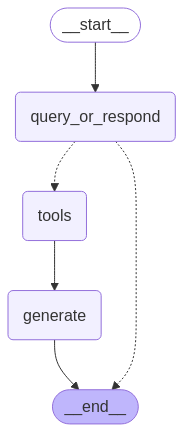

In [35]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [36]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()
graph = graph_builder.compile(checkpointer=memory)

# Specify an ID for the thread
config = {"configurable": {"thread_id": "abc123"}}

In [37]:
input_message = "hello"

for step in graph.stream(
    {"messages": [{"role": "user", "content": input_message}]},
    stream_mode="values",
    config=config,
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

hello
================================== Ai Message ==================================

Hello! How can I help you today?


In [39]:
input_message = "Which policies enabled the EU to remove trade barriers?"

for step in graph.stream(
    {"messages": [{"role": "user", "content": input_message}]},
    stream_mode="values",
    config=config,
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

Which policies enabled the EU to remove trade barriers?
================================== Ai Message ==================================
Tool Calls:
  retrieve (eaa803dc-cfe2-444e-9953-1bc65cabe6f5)
 Call ID: eaa803dc-cfe2-444e-9953-1bc65cabe6f5
  Args:
    query: policies that enabled the EU to remove trade barriers
================================= Tool Message =================================
Name: retrieve

Source: {'start_index': 0, '_id': '23d219bf2b2e452ba58fffd77035fb31', '_collection_name': 'data_collection'}
Content: While the concept of a "social market economy" was only introduced into EU law in 2007, free movement and trade were central to European development since the Treaty of Rome 1957. According to the standard theory of comparative advantage, two countries can both benefit from trade even if one of them has a less productive economy in all respects. Like in other regional organisations

## TODO 5: Monitor your agent in LangSmith.

If you have set up correctly, you can just visit the LangSmith website and see that your tracings are logged into your LangSmith project.

Capture your screen like this and upload it to MCV.

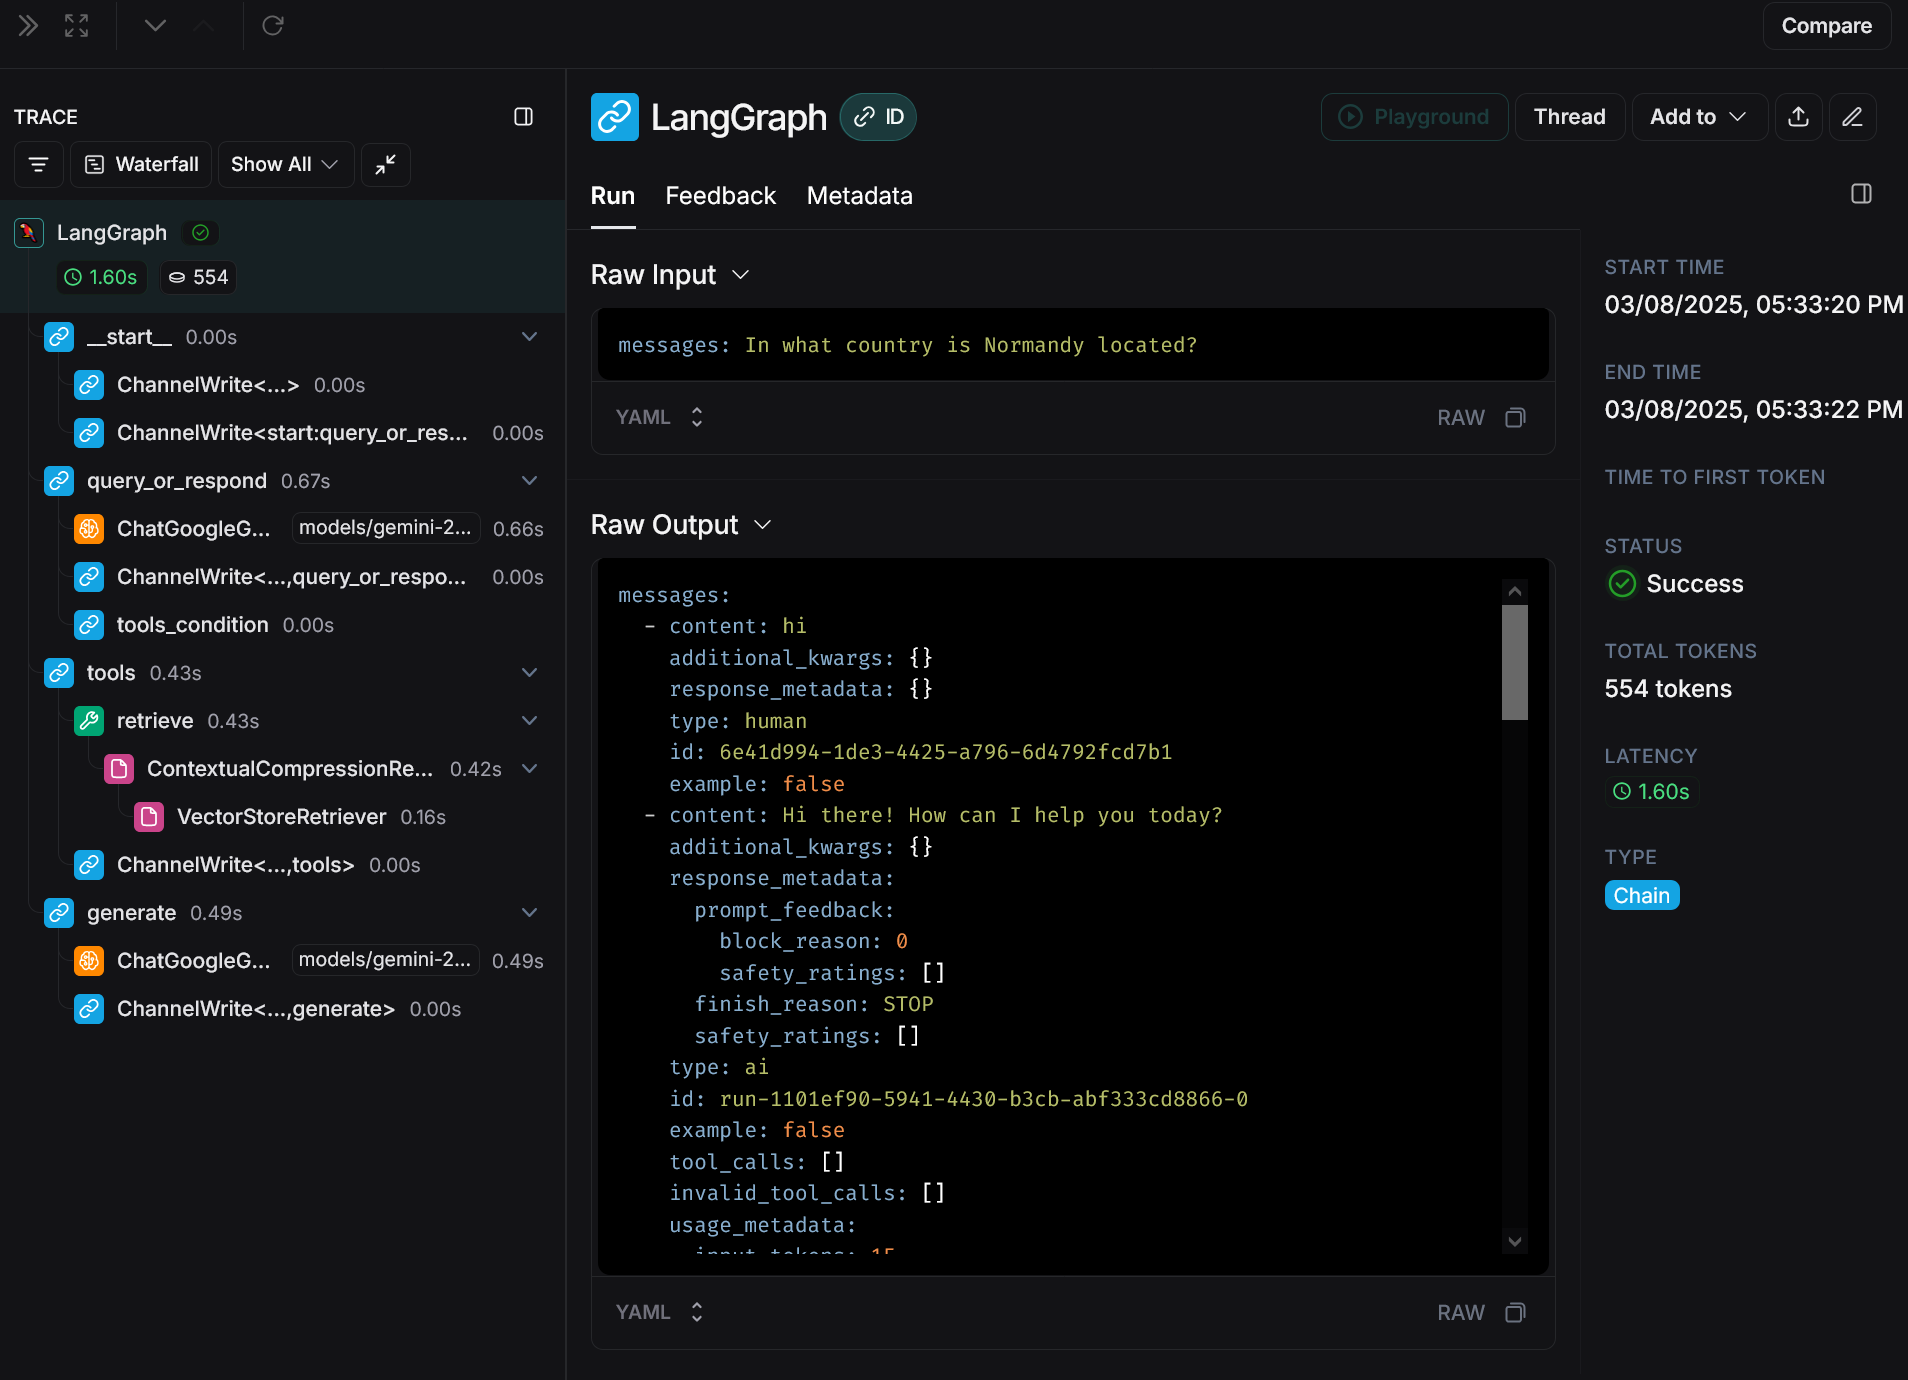

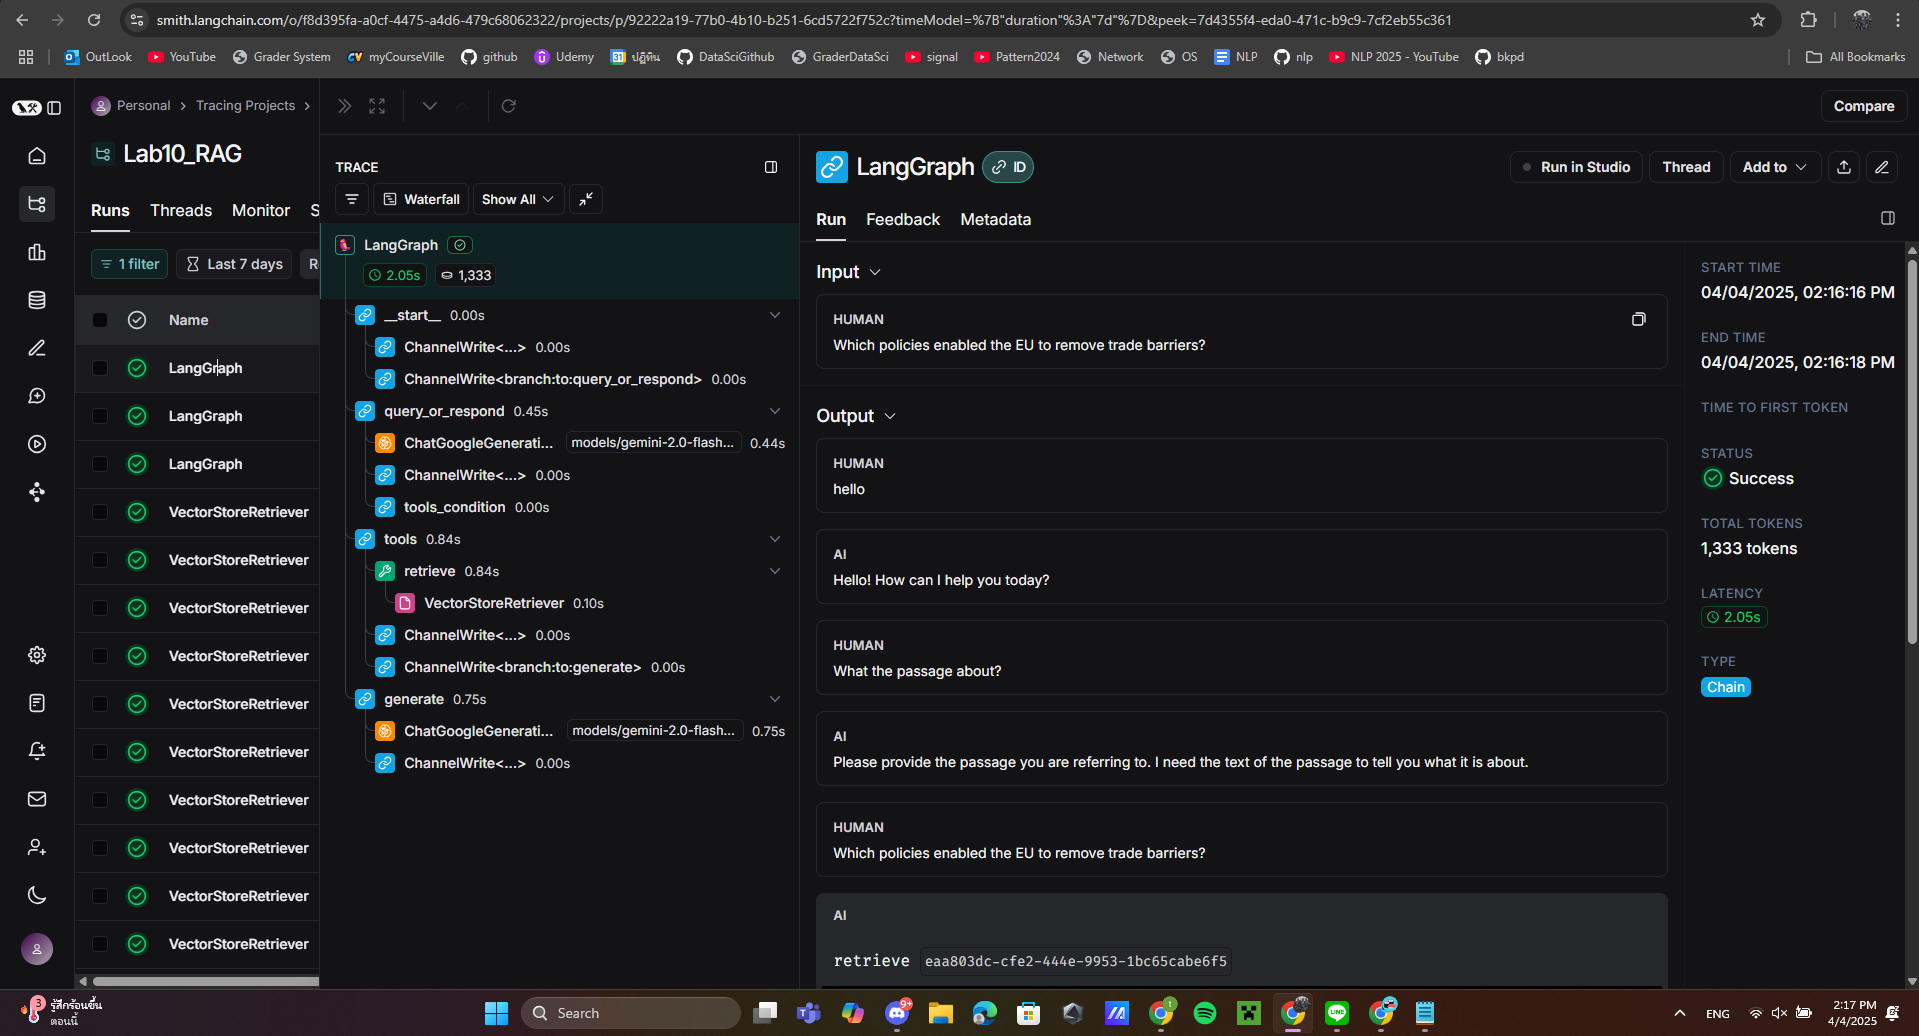